<p class="lead">The paper rests on a result that sounds like a paradox: a model
can look at a molecule, know nothing about biology, and still guess which database the molecule
was downloaded from. This notebook is the territory behind that claim. We will build the model,
score it properly, and then spend as much effort on what its score does <em>not</em> mean as on
obtaining it. The experiment comes from Section 2.2 of Farías-Abarca et al.
<sup class="c"><a href="#r1">[1]</a></sup>, and it is the move on which the whole paper turns.</p>

<div class="box key">
<h4>Learning objectives</h4>
<ul class="objectives">
<li>State the provenance experiment as a falsifiable prediction, and say what result would have
refuted the paper's argument.</li>
<li>Explain supervised classification in terms of features, labels and a decision function, and
describe a random forest as bagged decision trees with feature subsampling.</li>
<li>Build a confusion matrix by hand from six molecules and derive sensitivity, specificity, ROC
AUC and the Matthews correlation coefficient from it; explain why AUC is threshold-free, why MCC is
the right companion under imbalance, and why accuracy is not reported.</li>
<li>Run <em>k</em>-fold cross-validation, say what the folds estimate, compute a standard error and
a bootstrap interval, and reproduce the paper's database- and publication-provenance AUCs.</li>
<li>Explain why two AUCs measured on different tasks cannot be compared directly, and say what the
paper does instead.</li>
<li>Compute Shannon entropy, normalised conditional entropy and adjusted mutual information from
their definitions, and interpret them on this dataset.</li>
<li>Use permutation importance to identify which descriptors carry the provenance signal.</li>
</ul>
</div>

<p><b>How to read this notebook.</b> Read it once in order — every number in the text comes from
the cell above it — then re-run cells changing <em>one</em> thing at a time and watch which numbers
move. A <b>key idea</b> box states something to reproduce from memory, a <b>warning</b> box names a
common mistake, and a <b>bridge</b> box links to another notebook. Exercises modify the cell
immediately above them.</p>

<div class="box bridge">
<h4>Where this sits in the series</h4>
<p>Notebook 1 built the representation used here — 25 physicochemical descriptors and the ECFP4
fingerprint. This notebook asks whether that representation encodes provenance; Notebook 3 asks
whether our validation design is honest, and Notebook 4 what a residual difference proves.</p>
</div>

In [1]:
# --- setup: imports, deterministic seeds, and data access ------------------
# In Google Colab the next line installs RDKit (about 30 s). Locally it is a
# no-op because RDKit is already present.
!pip -q install rdkit 2>/dev/null

import io, os, urllib.request
import numpy as np, pandas as pd, matplotlib.pyplot as plt

RANDOM_STATE = 42          # the seed used throughout the published analysis
np.random.seed(RANDOM_STATE)
pd.set_option("display.width", 110, "display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 120, "font.size": 9, "axes.grid": False,
                     "axes.spines.top": False, "axes.spines.right": False})

REPO = "https://raw.githubusercontent.com/DanielBustosG/Urease-provenance-audit/main/"
LOCAL = next((p for p in ("data", "../data", "../../data") if os.path.isdir(p)), None)

def fetch(relpath):
    """Return a file-like object for a path inside the published repository.

    Looks for a local copy first so the notebook works offline; falls back to
    the raw file on GitHub, which is what happens in Colab.
    """
    local_map = {"data/processed/": "processed/", "results/tables/": "tables/"}
    if LOCAL:
        for prefix, sub in local_map.items():
            if relpath.startswith(prefix):
                cand = os.path.join(LOCAL, sub, os.path.basename(relpath))
                if os.path.exists(cand):
                    return open(cand, "rb")
        cand = os.path.join(LOCAL, os.path.basename(relpath))
        if os.path.exists(cand):
            return open(cand, "rb")
    with urllib.request.urlopen(REPO + relpath, timeout=60) as r:
        return io.BytesIO(r.read())

def load_table(relpath, **kw):
    """Read a .parquet or .csv from the repository into a DataFrame."""
    buf = fetch(relpath)
    return (pd.read_parquet(buf, **kw) if relpath.endswith(".parquet")
            else pd.read_csv(buf, **kw))

print("pandas", pd.__version__, "| numpy", np.__version__,
      "| data source:", "local ./%s" % LOCAL if LOCAL else "GitHub (raw)")

pandas 3.0.3 | numpy 2.4.6 | data source: local ./../data


The cell above fixes `RANDOM_STATE = 42`, the seed of the published analysis, and gives us
`load_table()`. Everything below reads the paper's own published files; nothing is simulated.
We also need scikit-learn and RDKit, which we import where they are first used so that you can
see which tool does what.

## 1. The question, stated so that it can be wrong

A cross-collection comparison works like this. You take a target-focused library — here UI-Ref,
1,218 molecules that have been reported in a urease assay — and an external reference library
such as the Drug Repurposing Hub. You compute descriptors for both, train a classifier to tell
them apart, and obtain a high AUC. The usual reading is that urease inhibitors occupy a distinct
region of chemical space, and that the descriptors the model relies on describe urease-relevant
chemistry.

The paper's objection is not that the AUC is wrong. It is that a second explanation predicts the
same AUC. Molecules do not arrive in a library at random: they arrive because a particular
laboratory synthesised a particular congeneric series, published it in a particular journal, and
a particular curator deposited it in a particular database. If those administrative facts leave a
descriptor-level signature, then a classifier separating two libraries may be reading the
signature of library assembly rather than the chemistry of the target.

That is a hypothesis about the world, and the paper turns it into a prediction that could fail:

<div class="box key">
<h4>The falsifiable prediction</h4>
<p>If descriptor-based separation between collections reflects target chemistry, then
<em>within</em> a single target-focused collection — where every molecule has been reported in a
urease assay, so target chemistry is held constant — a classifier should <b>not</b> be able to
recover which database deposited a molecule, nor which paper reported it. Provenance should look
like noise.</p>
<p>If instead the classifier recovers provenance easily, then descriptors carry provenance
information, and cross-collection separation can no longer be read as evidence about the target
without an explicit provenance control.</p>
</div>

Note the logic. Holding reference-set membership constant is what makes the experiment
interpretable: a molecule is not more or less of a urease inhibitor because PubChem rather than
BindingDB holds the record, so any signal the model finds is a property of how the record was made.
An AUC near 0.5 would have supported the conventional reading. Before running anything, write down
what you expect.

In [2]:
# UI-Ref: one row per molecule, with provenance and 25 RDKit descriptors.
ui = load_table("data/processed/uiref_analysis.parquet")

DESC = ["MolWt", "ExactMolWt", "NumHeavyAtoms", "NumAtoms", "LogP", "MolMR", "TPSA",
        "HBA", "HBD", "RotatableBonds", "RingCount", "AromaticRings", "AliphaticRings",
        "FractionCSP3", "BertzCT", "FormalCharge", "NumAmideBonds", "NumHeteroAtoms",
        "NumAromaticHeterocycles", "NumAliphaticHeterocycles", "NumAromaticCarbocycles",
        "NumAliphaticCarbocycles", "HeavyAtomMolWt", "NHOHCount", "NOCount"]

print("molecules:", len(ui), "| descriptors used as features:", len(DESC))
print("\ncombinations of depositing databases (source_dbs):")
print(ui["source_dbs"].value_counts().to_string())
print("\nmolecules found in exactly one / two / three databases:")
print(ui["n_source_dbs"].value_counts().sort_index().to_string())

molecules: 1218 | descriptors used as features: 25

combinations of depositing databases (source_dbs):
source_dbs
PubChem                     581
BindingDB|ChEMBL|PubChem    173
BindingDB                   161
BindingDB|ChEMBL            141
ChEMBL|PubChem               73
BindingDB|PubChem            67
ChEMBL                       22

molecules found in exactly one / two / three databases:
n_source_dbs
1    764
2    281
3    173


Of the 1,218 molecules, 764 appear in exactly one database, 281 in two and 173 in all three. The
paper restricts the provenance experiment to the <em>source-exclusive</em> molecules — those found
in one database only — because for them the label "depositing database" is unambiguous
<sup class="c"><a href="#r1">[1]</a></sup>. Among those, 581 are PubChem-only
<sup class="c"><a href="#r20">[20]</a></sup>, 161 BindingDB-only
<sup class="c"><a href="#r19">[19]</a></sup> and 22 ChEMBL-only
<sup class="c"><a href="#r18">[18]</a></sup>. The headline experiment is the largest pair,
PubChem against BindingDB: 742 molecules in total.

Before fitting anything, look at the raw material. If provenance were invisible to descriptors,
the two groups would have indistinguishable descriptor distributions.

In [3]:
excl = ui[ui["n_source_dbs"] == 1]
pair = excl[excl["source_dbs"].isin(["PubChem", "BindingDB"])].copy()
print("n =", len(pair), "| PubChem-only:", (pair.source_dbs == "PubChem").sum(),
      "| BindingDB-only:", (pair.source_dbs == "BindingDB").sum())

print("\nmean descriptor values by depositing database:")
print(pair.groupby("source_dbs")[["LogP", "MolMR", "MolWt", "TPSA",
                                  "FractionCSP3", "AromaticRings"]].mean().round(2).to_string())

n = 742 | PubChem-only: 581 | BindingDB-only: 161

mean descriptor values by depositing database:
            LogP  MolMR   MolWt   TPSA  FractionCSP3  AromaticRings
source_dbs                                                         
BindingDB   3.83  94.06  345.31  70.98          0.12           2.85
PubChem     2.04  70.58  277.39  74.99          0.25           1.52


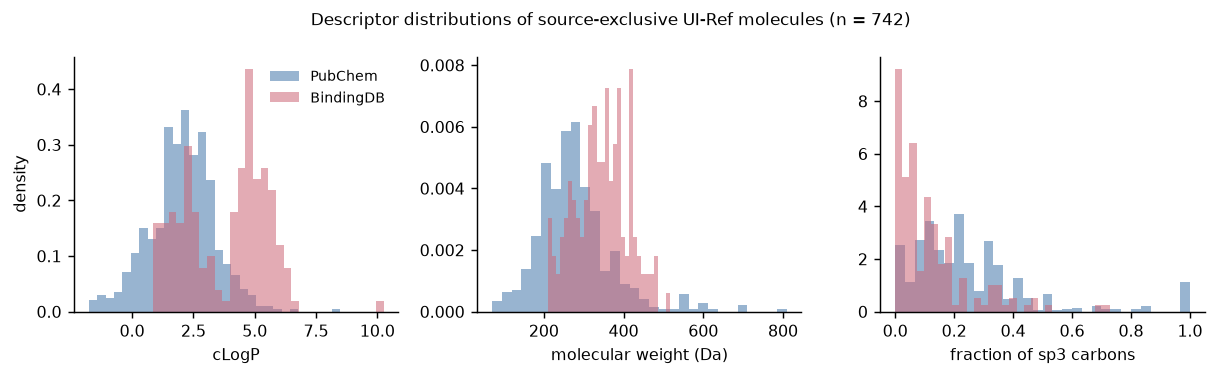

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(9.5, 2.9))
for ax, col, xlab in zip(axes, ["LogP", "MolWt", "FractionCSP3"],
                         ["cLogP", "molecular weight (Da)", "fraction of sp3 carbons"]):
    for db, colour in [("PubChem", "#4477aa"), ("BindingDB", "#cc6677")]:
        v = pair.loc[pair.source_dbs == db, col]
        ax.hist(v, bins=30, density=True, alpha=0.55, color=colour, label=db)
    ax.set_xlabel(xlab)
    ax.set_ylabel("density" if col == "LogP" else "")
axes[0].legend(frameon=False, fontsize=8)
fig.suptitle("Descriptor distributions of source-exclusive UI-Ref molecules (n = 742)",
             fontsize=9.5)
fig.tight_layout()

<p class="caption"><b>Figure 1.</b> Descriptor distributions of the 742 source-exclusive UI-Ref
molecules by depositing database. BindingDB-only molecules are on average more lipophilic (mean
cLogP 3.83 against 2.04), heavier (345 Da against 277 Da) and less saturated (FractionCSP3 0.12
against 0.25), but the distributions overlap heavily, so no single descriptor separates them.</p>

The means differ, but the histograms overlap. A student who stops here would conclude that
provenance is weakly visible at best. That intuition is wrong, and the reason it is wrong is the
subject of the next three sections: a classifier does not look at one descriptor at a time.

## 2. Supervised classification from scratch

### 2.1 Features, labels and a decision function

**The problem it solves.** You have a collection of objects for which some property is known, and
you want a rule that assigns that property to objects for which it is not known. "Supervised"
means the known answers — the labels — are used during fitting.

Formally, each molecule $i$ is described by a **feature vector**
$\mathbf{x}_i = (x_{i1}, \dots, x_{ip}) \in \mathbb{R}^{p}$. Here $p = 25$ and the entries are the
RDKit descriptors of Notebook 1. Each molecule also carries a **label** $y_i \in \{0, 1\}$: in our
experiment $y_i = 1$ if the molecule is PubChem-exclusive and $y_i = 0$ if it is
BindingDB-exclusive. The pairs $(\mathbf{x}_i, y_i)$ form the **training set**.

A classifier is a pair of objects. The first is a **score function**
$s : \mathbb{R}^{p} \rightarrow [0, 1]$ that maps a feature vector to a number, conventionally read
as an estimate of $\Pr(y = 1 \mid \mathbf{x})$. The second is a **threshold** $t$ that converts the
score into a decision:

$$\hat{y}(\mathbf{x}) = \begin{cases} 1 & \text{if } s(\mathbf{x}) \ge t \\ 0 & \text{otherwise.}\end{cases}$$

Separating the score from the threshold is not pedantry; it is the distinction on which the whole
of Section 3 rests. The score is a property of the fitted model. The threshold is a decision you
impose afterwards, and you can change it without refitting anything.

**Where it fails.** Nothing in this formalism says the label has to mean something. The
mathematics will not object to a purely administrative label, the AUC will not warn you, and the
feature attributions will dutifully report which descriptors were useful. Deciding whether a label
corresponds to a real-world distinction is the analyst's job, never the model's — and this notebook
exploits that deliberately, fitting a classifier to a label known to be scientifically meaningless
in order to measure how much provenance structure the descriptors carry.

### 2.2 Decision trees

**The problem it solves.** We need a score function flexible enough to use several descriptors
jointly, with interactions, without our having to specify the functional form in advance.

A **decision tree** partitions feature space by asking a sequence of threshold questions. At each
internal node the tree selects one feature $j$ and one cut point $c$, and sends molecules with
$x_{j} \le c$ to the left child and the rest to the right. At a leaf it stops and predicts the
class proportions of the training molecules that landed there.

How is $(j, c)$ chosen? By minimising an impurity measure. For a node containing a fraction $p_1$
of positives and $p_0 = 1 - p_1$ of negatives, the **Gini impurity** is

$$G = 1 - p_0^2 - p_1^2 = 2\,p_0 p_1 ,$$

which is $0$ when the node is pure and $0.5$ when the classes are balanced. The tree evaluates
every feature and every candidate cut point, and keeps the split that maximises the weighted
impurity decrease

$$\Delta G = G_{\text{parent}} - \frac{n_L}{n} G_L - \frac{n_R}{n} G_R .$$

Let us see the first question a tree asks about our molecules.

In [5]:
from sklearn.tree import DecisionTreeClassifier, export_text

X = pair[DESC].values
y = (pair["source_dbs"] == "PubChem").astype(int).values     # 1 = PubChem, 0 = BindingDB

stump = DecisionTreeClassifier(max_depth=2, random_state=RANDOM_STATE).fit(X, y)
print(export_text(stump, feature_names=DESC, decimals=2))
print("Gini impurity of the root node: 2*p0*p1 =",
      round(2 * y.mean() * (1 - y.mean()), 4))

|--- LogP <= 4.14
|   |--- FractionCSP3 <= 0.07
|   |   |--- class: 1
|   |--- FractionCSP3 >  0.07
|   |   |--- class: 1
|--- LogP >  4.14
|   |--- BertzCT <= 1529.67
|   |   |--- class: 0
|   |--- BertzCT >  1529.67
|   |   |--- class: 1

Gini impurity of the root node: 2*p0*p1 = 0.3398


The tree's first question is about cLogP, and the cut point is close to the value that separates
the two group means seen in Figure 1. Read the printed tree as a nested rule: molecules with low
cLogP are mostly PubChem (`class: 1`), molecules with high cLogP mostly BindingDB (`class: 0`), and
the depth-2 nodes refine this using a second descriptor. The root Gini impurity is about 0.34,
reflecting the 581:161 class split.

**Where it fails.** A tree grown to full depth splits until every leaf is pure, memorising the
training set including its noise, and its predictions are unstable: move a few molecules and a
different descriptor may win at the root, changing the whole subtree. Low bias, very high
variance.

### 2.3 Bagging and feature subsampling: the random forest

**The problem it solves.** Variance. If a procedure is unbiased but noisy, averaging many
independent copies of it reduces the noise without introducing bias.

**Bagging** (bootstrap aggregating) does exactly that <sup class="c"><a href="#r3">[3]</a></sup>.
Draw $B$ bootstrap samples from the training set — each a sample of $n$ molecules taken with
replacement, so roughly 63% of the molecules appear at least once and the rest are left out — fit
one tree to each, and average their predicted probabilities:

$$s(\mathbf{x}) = \frac{1}{B} \sum_{b=1}^{B} s_b(\mathbf{x}).$$

If the $B$ trees made independent errors, the variance of the average would fall as $1/B$. They do
not: trained on overlapping data, they tend to pick the same strong feature at the root and are
therefore correlated. Writing $\rho$ for the average pairwise correlation between tree predictions
and $\sigma^2$ for the variance of one tree, the variance of the average is

$$\rho \sigma^{2} + \frac{1 - \rho}{B}\,\sigma^{2},$$

so increasing $B$ removes the second term but never the first. The only way to reduce the floor is
to make the trees less alike.

That is Breiman's addition in the **random forest** <sup class="c"><a href="#r2">[2]</a></sup>: at
every split, the tree may only consider a random subset of the features, by default
$\lfloor\sqrt{p}\rfloor = 5$ of our 25 descriptors. A tree that is forbidden from using cLogP at
the root must find a different route to the same information, so the ensemble explores correlated
descriptors that a single greedy tree would have ignored. Lowering $\rho$ lowers the variance
floor.

<div class="box key">
<h4>Random forest in one sentence</h4>
<p>A random forest is an average over many deliberately decorrelated decision trees: each tree
sees a bootstrap resample of the molecules and, at every split, a random subset of the
descriptors. It inherits the trees' ability to model interactions and non-linear thresholds, and
replaces their instability with an average.</p>
</div>

Three properties make this a sensible default for tabular descriptor data, and they are why the
paper uses it <sup class="c"><a href="#r1">[1]</a></sup>: threshold splits depend only on the
ordering of a feature's values, so no standardisation is needed and molecular weight in daltons can
sit beside FractionCSP3 on $[0,1]$; interactions and non-monotone effects are modelled without being
specified; and more trees never hurt accuracy, they only cost time.

The next cell shows the variance reduction directly.

In [6]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score

Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, stratify=y,
                                      random_state=RANDOM_STATE)

rows = []
for B in [1, 2, 5, 10, 30, 100, 300]:
    aucs = [roc_auc_score(yte, RandomForestClassifier(
                n_estimators=B, class_weight="balanced", random_state=s, n_jobs=-1)
            .fit(Xtr, ytr).predict_proba(Xte)[:, 1]) for s in range(5)]
    rows.append((B, np.mean(aucs), np.std(aucs, ddof=1)))

bag = pd.DataFrame(rows, columns=["n_trees", "mean_AUC", "SD_over_5_seeds"]).round(4)
print(bag.to_string(index=False))

 n_trees  mean_AUC  SD_over_5_seeds
       1    0.8431           0.0227
       2    0.8971           0.0295
       5    0.9356           0.0103
      10    0.9446           0.0103
      30    0.9536           0.0050
     100    0.9539           0.0027
     300    0.9552           0.0020


Two things happen as the forest grows. The mean AUC on the held-out 30% rises and then flattens:
one tree reaches about 0.80, ten trees about 0.93, and beyond roughly a hundred trees the
improvement is in the third decimal. The standard deviation across five random seeds collapses
from above 0.02 for a single tree to below 0.005 for 300 trees — this is the variance reduction
the averaging buys. The published analysis uses 300 trees with class-balanced weights
<sup class="c"><a href="#r1">[1]</a></sup>, which the table shows is comfortably inside the flat
region.

<div class="exercise">
<h4>Exercise 1</h4>
<p>Re-run the cell above with <code>max_features=25</code> added to the
<code>RandomForestClassifier</code> call, which forces every split to consider all descriptors and
so turns the forest into plain bagging. Does the AUC at 300 trees go up or down, and what does
that tell you about the value of feature subsampling for this particular feature set?</p>
</div>

<div class="box warn">
<h4>"Balanced class weights" are not resampling</h4>
<p><code>class_weight="balanced"</code> multiplies each class's contribution to the impurity
criterion by $n / (2 n_k)$, so the 161 BindingDB molecules collectively count as much as the 581
PubChem molecules. It changes the fitting criterion, not the data, and it does not change the
class prior in the test folds. Students often assume it makes the problem balanced; it does not,
which is one reason the evaluation metrics of the next section still have to cope with
imbalance.</p>
</div>

## 3. Scoring a classifier: everything comes from the confusion matrix

### 3.1 Six molecules, worked by hand

**The problem it solves.** A fitted classifier returns scores. We need a small number that says
how good they are — and we need to know what that number ignores.

Every classification metric in this paper is a function of four counts. Fix a threshold, call one
class **positive**, and tabulate:

| | predicted positive | predicted negative |
|---|---|---|
| **actually positive** | true positive (TP) | false negative (FN) |
| **actually negative** | false positive (FP) | true negative (TN) |

Let us fill this table in by hand. Take six real UI-Ref molecules — the first three
PubChem-exclusive and the first three BindingDB-exclusive — and use the crudest possible rule:
*predict BindingDB if cLogP $\ge 3$*. Here "positive" means BindingDB.

| row_id | true source | cLogP | predicted | cell |
|---|---|---|---|---|
| UIREF-0001 | PubChem | 5.27 | BindingDB | FP |
| UIREF-0002 | PubChem | 2.73 | PubChem | TN |
| UIREF-0003 | PubChem | 2.56 | PubChem | TN |
| UIREF-0018 | BindingDB | 5.65 | BindingDB | TP |
| UIREF-0022 | BindingDB | 1.24 | PubChem | FN |
| UIREF-0037 | BindingDB | 4.75 | BindingDB | TP |

So TP = 2, FP = 1, FN = 1, TN = 2. From these four numbers:

$$\text{sensitivity (TPR)} = \frac{TP}{TP + FN} = \frac{2}{3} = 0.667, \qquad
\text{specificity} = \frac{TN}{TN + FP} = \frac{2}{3} = 0.667,$$

$$\text{false positive rate (FPR)} = 1 - \text{specificity} = \frac{1}{3}, \qquad
\text{accuracy} = \frac{TP + TN}{6} = \frac{4}{6} = 0.667 .$$

The next cell confirms that the six molecules and the four counts are what the hand table claims.

In [7]:
from sklearn.metrics import confusion_matrix, matthews_corrcoef

ex = pd.concat([pair[pair.source_dbs == "PubChem"].head(3),
                pair[pair.source_dbs == "BindingDB"].head(3)])[
    ["row_id", "source_dbs", "LogP"]].copy()
ex["y_true"] = (ex.source_dbs == "BindingDB").astype(int)     # positive = BindingDB
ex["y_pred"] = (ex.LogP >= 3.0).astype(int)                   # the hand-made rule
print(ex.round(2).to_string(index=False))

tn, fp, fn, tp = confusion_matrix(ex.y_true, ex.y_pred).ravel()
print("\nTP =", tp, "FP =", fp, "FN =", fn, "TN =", tn)
sens, spec = tp / (tp + fn), tn / (tn + fp)
print(f"sensitivity = {sens:.3f} | specificity = {spec:.3f}"
      f" | accuracy = {(tp + tn) / len(ex):.3f}")

    row_id source_dbs  LogP  y_true  y_pred
UIREF-0001    PubChem  5.27       0       1
UIREF-0002    PubChem  2.73       0       0
UIREF-0003    PubChem  2.56       0       0
UIREF-0018  BindingDB  5.65       1       1
UIREF-0022  BindingDB  1.24       1       0
UIREF-0037  BindingDB  4.75       1       1

TP = 2 FP = 1 FN = 1 TN = 2
sensitivity = 0.667 | specificity = 0.667 | accuracy = 0.667


### 3.2 The ROC curve and its area

**The problem it solves.** The four counts above describe the rule *at one threshold*. Change the
threshold from 3.0 to 2.0 and every count changes. Reporting a single confusion matrix therefore
confounds two different questions: how well the score ranks molecules, and whether the particular
cut point you chose was a good one.

The **receiver operating characteristic** curve separates them. Sweep the threshold from $+\infty$
down to $-\infty$; at each value compute (FPR, TPR) and plot the pair. At the highest threshold
nothing is called positive, so the curve starts at $(0,0)$; at the lowest everything is, so it ends
at $(1,1)$. The **area under this curve** (ROC AUC) summarises the whole sweep in one number
<sup class="c"><a href="#r4">[4]</a></sup>.

The area has an exact combinatorial meaning that is far more useful than the geometry. Take every
positive–negative pair of molecules and ask whether the positive one received the higher score:

$$\mathrm{AUC} \;=\; \frac{1}{n_{+} n_{-}} \sum_{i:\,y_i = 1} \;\sum_{j:\,y_j = 0}
\Big[ \mathbf{1}\big(s_i > s_j\big) + \tfrac{1}{2}\mathbf{1}\big(s_i = s_j\big) \Big].$$

In words: **AUC is the probability that a randomly chosen positive outranks a randomly chosen
negative.** It is therefore threshold-free — it depends only on the ordering of the scores, not on
their calibration or on where you cut. An AUC of 0.5 is the value of random ranking, and 1.0 is a
perfect separation.

With six molecules we can count the pairs by hand. Use cLogP itself as the score for class
BindingDB. The three positives score 5.65, 1.24 and 4.75; the three negatives score 5.27, 2.73 and
2.56. There are $3 \times 3 = 9$ pairs. Molecule 5.65 beats all three negatives (3 wins); 1.24
beats none (0); 4.75 beats 2.73 and 2.56 but loses to 5.27 (2). Total $3 + 0 + 2 = 5$, so

$$\mathrm{AUC} = \frac{5}{9} = 0.556 .$$

In [8]:
from sklearn.metrics import roc_curve

print("sklearn AUC on the six molecules:",
      round(roc_auc_score(ex.y_true, ex.LogP), 4), " (5/9 =", round(5 / 9, 4), ")")

# count the concordant pairs explicitly, as in the hand calculation
pos = ex.loc[ex.y_true == 1, "LogP"].values
neg = ex.loc[ex.y_true == 0, "LogP"].values
wins = sum((p > n) + 0.5 * (p == n) for p in pos for n in neg)
print("concordant positive-negative pairs:", wins, "of", len(pos) * len(neg))

fpr, tpr, thr = roc_curve(ex.y_true, ex.LogP)
print("\nthreshold sweep (sklearn drops redundant points):")
print(pd.DataFrame({"threshold": thr.round(2), "FPR": fpr.round(3),
                    "TPR": tpr.round(3)}).to_string(index=False))

sklearn AUC on the six molecules: 0.5556  (5/9 = 0.5556 )
concordant positive-negative pairs: 5.0 of 9

threshold sweep (sklearn drops redundant points):
 threshold   FPR   TPR
       inf 0.000 0.000
      5.65 0.000 0.333
      5.27 0.333 0.333
      4.75 0.333 0.667
      2.56 1.000 0.667
      1.24 1.000 1.000


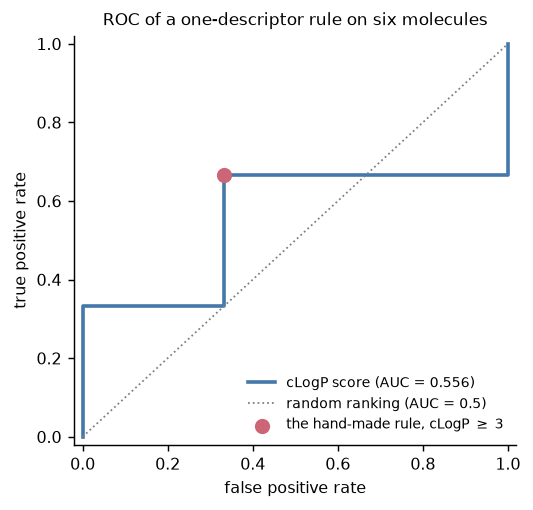

In [9]:
fig, ax = plt.subplots(figsize=(4.2, 4.0))
ax.step(fpr, tpr, where="post", color="#4477aa", lw=2, label="cLogP score (AUC = 0.556)")
ax.plot([0, 1], [0, 1], ls=":", color="grey", lw=1, label="random ranking (AUC = 0.5)")
ax.scatter([1 / 3], [2 / 3], s=55, color="#cc6677", zorder=5,
           label="the hand-made rule, cLogP $\\geq$ 3")
ax.set_xlabel("false positive rate"); ax.set_ylabel("true positive rate")
ax.set_xlim(-0.02, 1.02); ax.set_ylim(-0.02, 1.02)
ax.set_title("ROC of a one-descriptor rule on six molecules", fontsize=9.5)
ax.legend(frameon=False, fontsize=7.5, loc="lower right")
fig.tight_layout()

<p class="caption"><b>Figure 2.</b> The complete ROC curve of a single-descriptor score on the six
hand-worked molecules. The red point is the one confusion matrix computed in Section 3.1, at
FPR = 1/3 and TPR = 2/3; the staircase is what happens to that point as the threshold moves. The
area under the staircase is 5/9 = 0.556, the fraction of positive–negative pairs ranked correctly,
barely above the 0.5 of random ranking. A single threshold is one point on this curve; the AUC is
the curve.</p>

Two lessons. The red dot shows why a confusion matrix alone is insufficient: it is one point of a
curve, and another cut point gives different counts from the same model. And 0.556 on nine pairs
tells us nothing reliable. Both problems are solved by more data and cross-validation, not by a
better metric.

### 3.3 The Matthews correlation coefficient

**The problem it solves.** AUC describes ranking. It says nothing about whether the classifier,
*at the threshold you will actually use*, makes balanced mistakes. Under class imbalance a model
can rank well and still produce a confusion matrix dominated by one class.

The **Matthews correlation coefficient** is the Pearson correlation between the true and predicted
binary labels, written in terms of the four counts <sup class="c"><a href="#r5">[5]</a></sup>:

$$\mathrm{MCC} = \frac{TP \cdot TN - FP \cdot FN}{\sqrt{(TP+FP)(TP+FN)(TN+FP)(TN+FN)}} .$$

It ranges from $-1$ (every prediction inverted) through $0$ (no association) to $+1$ (perfect). Its
defining property is that all four cells appear in the numerator *and* all four marginals in the
denominator, so a classifier cannot score well by neglecting the minority class
<sup class="c"><a href="#r6">[6]</a></sup>. For our hand example,

$$\mathrm{MCC} = \frac{2 \cdot 2 - 1 \cdot 1}{\sqrt{3 \cdot 3 \cdot 3 \cdot 3}} = \frac{3}{9} = 0.333 .$$

### 3.4 Why this paper does not report accuracy

**Accuracy** is $(TP+TN)/n$: the fraction of correct calls. It is the most intuitive metric and the
least informative one here, because it has a high floor that carries no information. In our
provenance task 581 of 742 molecules are PubChem-exclusive, so a model that ignores every
descriptor and always answers "PubChem" is 78.3% accurate. Any accuracy below that is worse than
useless; any accuracy above it has to be judged against a baseline the reader must compute for
themselves. MCC has no such floor: the always-PubChem model gets exactly 0.

In [10]:
from sklearn.metrics import accuracy_score, balanced_accuracy_score

trivial = np.ones_like(y)                     # always predict the majority class, PubChem
rule    = (pair["LogP"].values < 3.0).astype(int)   # low cLogP -> PubChem, the one-rule model

print("hand example, MCC = (2*2 - 1*1)/sqrt(3*3*3*3) =", round(3 / 9, 4),
      "| sklearn:", round(matthews_corrcoef(ex.y_true, ex.y_pred), 4))
print("\nfull PubChem-vs-BindingDB task, n =", len(y), " prevalence of PubChem =",
      round(y.mean(), 3))
cmp_ = pd.DataFrame(
    {"accuracy":          [accuracy_score(y, trivial), accuracy_score(y, rule)],
     "balanced_accuracy": [balanced_accuracy_score(y, trivial), balanced_accuracy_score(y, rule)],
     "MCC":               [matthews_corrcoef(y, trivial), matthews_corrcoef(y, rule)]},
    index=["always predict PubChem", "rule: cLogP < 3 -> PubChem"]).round(3)
print(cmp_.to_string())

hand example, MCC = (2*2 - 1*1)/sqrt(3*3*3*3) = 0.3333 | sklearn: 0.3333

full PubChem-vs-BindingDB task, n = 742  prevalence of PubChem = 0.783
                            accuracy  balanced_accuracy    MCC
always predict PubChem         0.783              0.500  0.000
rule: cLogP < 3 -> PubChem     0.749              0.703  0.364


The model that looks at nothing is 78.3% accurate; the one-descriptor rule is 74.9% accurate, i.e.
*less* accurate, yet its MCC is 0.364 against 0.000 and its balanced accuracy 0.722 against 0.500.
Accuracy ranks a useful rule below a useless one, which is why the paper reports AUC and MCC and
does not report accuracy <sup class="c"><a href="#r1">[1]</a></sup>.

<div class="box key">
<h4>Which metric answers which question</h4>
<ul>
<li><b>ROC AUC</b> — does the score <em>rank</em> positives above negatives? Threshold-free,
insensitive to the class prior, blind to calibration.</li>
<li><b>MCC</b> — at the threshold in use, are the four cells of the confusion matrix jointly
sensible? Threshold-dependent, sensitive to imbalance in the right way.</li>
<li><b>Accuracy</b> — what fraction of calls are correct? Dominated by the majority class;
report the majority-class baseline alongside it or do not report it at all.</li>
</ul>
</div>

<div class="box warn">
<h4>AUC is not immune to everything</h4>
<p>AUC is invariant to the class prior in the sense that it does not change if you duplicate
negatives, but it is <em>not</em> a good summary when the positive class is very rare and you care
about the top of the ranking: a model can achieve AUC 0.95 while almost every top-ranked molecule
is a false positive, because the sweep averages over regions of the curve nobody will ever use. In
that situation the area under the precision–recall curve is the more honest summary
<sup class="c"><a href="#r7">[7]</a></sup>. Our provenance task has a 22% minority class, which is
imbalanced but not rare, so AUC with MCC alongside it is adequate here.</p>
</div>

## 4. Cross-validation: what the folds estimate

**The problem it solves.** A model's performance on the molecules used to fit it is not an estimate
of anything useful — a fully grown tree scores perfectly on its own training data. We need an
estimate of performance on molecules the model has not seen, computed from a finite dataset we
cannot afford to throw half of away.

**$k$-fold cross-validation** splits the $n$ molecules into $k$ disjoint folds of roughly equal
size. For each fold $m = 1, \dots, k$ in turn, the model is fitted on the other $k - 1$ folds and
used to score the molecules in fold $m$. Every molecule is therefore scored exactly once by a model
that never saw it, and the $n$ out-of-fold scores can be pooled into a single ROC curve. When the
split preserves the class proportions in every fold, as it should under imbalance, it is called
**stratified** $k$-fold. The paper uses stratified 5-fold cross-validation for the
database-provenance task and stratified 3-fold for the document task, where the positive classes
are smaller <sup class="c"><a href="#r1">[1]</a></sup>.

What does the number estimate? Not the performance of any one model, since $k$ models were fitted,
but the performance of the *procedure* — "fit a 300-tree random forest to about
$\frac{k-1}{k} n$ molecules from this population" — on a new sample from the same population. The
phrase *from the same population* does an enormous amount of work, and Notebook 3 is about what
happens when it is false.

Two numbers are usually reported with the point estimate.

The **standard error across folds** treats the $k$ fold-level AUCs $a_1, \dots, a_k$ as $k$
observations and reports

$$\mathrm{SE} = \frac{1}{\sqrt{k}} \sqrt{\frac{1}{k-1}\sum_{m=1}^{k}\left(a_m - \bar{a}\right)^{2}} .$$

It is easy to compute and easy to over-interpret: the folds share training data, so the $a_m$ are
positively correlated and this SE is biased downward. Read it as a dispersion diagnostic — a fold
far from the others means the folds are not exchangeable — not as a standard error.

The **bootstrap percentile interval** resamples the molecules, not the folds. Draw $n$ out-of-fold
(score, label) pairs with replacement, recompute the AUC, repeat $R$ times, and take the 2.5th and
97.5th percentiles of the resulting distribution. This is what the paper reports as its 95%
confidence interval, with $R = 2{,}000$ resamples <sup class="c"><a href="#r1">[1]</a></sup>. We
use $R = 400$ below to stay inside the notebook's runtime budget; the interval is correspondingly
grainier in its last decimal but centred in the same place.

In [11]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict

rf = RandomForestClassifier(n_estimators=300, class_weight="balanced",
                            random_state=RANDOM_STATE, n_jobs=-1)
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# one out-of-fold score per molecule
oof = cross_val_predict(rf, X, y, cv=cv5, method="predict_proba", n_jobs=1)[:, 1]
auc_pooled = roc_auc_score(y, oof)

# the same five fits, scored fold by fold
fold_auc = []
for tr, te in cv5.split(X, y):
    m = RandomForestClassifier(n_estimators=300, class_weight="balanced",
                               random_state=RANDOM_STATE, n_jobs=-1).fit(X[tr], y[tr])
    fold_auc.append(roc_auc_score(y[te], m.predict_proba(X[te])[:, 1]))
fold_auc = np.array(fold_auc)

print("pooled out-of-fold AUC        :", round(auc_pooled, 4))
print("per-fold AUCs                 :", np.round(fold_auc, 4))
se_folds = fold_auc.std(ddof=1) / np.sqrt(len(fold_auc))
print(f"mean of folds +/- SE          : {fold_auc.mean():.4f} +/- {se_folds:.4f}")

pooled out-of-fold AUC        : 0.9544
per-fold AUCs                 : [0.9663 0.954  0.9406 0.9461 0.9647]
mean of folds +/- SE          : 0.9544 +/- 0.0050


In [12]:
rng = np.random.RandomState(RANDOM_STATE)
R = 400                      # the paper uses 2,000; 400 keeps this notebook under a minute
boot = []
for _ in range(R):
    idx = rng.randint(0, len(y), len(y))
    if len(np.unique(y[idx])) == 2:
        boot.append(roc_auc_score(y[idx], oof[idx]))
lo, hi = np.percentile(boot, [2.5, 97.5])
print(f"bootstrap 95% CI over {len(boot)} resamples: [{lo:.4f}, {hi:.4f}]")
print("published value (table S5)        : 0.9544 [0.9391, 0.9683]")

bootstrap 95% CI over 400 resamples: [0.9379, 0.9677]
published value (table S5)        : 0.9544 [0.9391, 0.9683]


### 4.1 The result

The pooled out-of-fold AUC is **0.9544**. The five folds give 0.9663, 0.9540, 0.9406, 0.9461 and
0.9647 — a spread of about 0.026 with a standard error of 0.005 — and the bootstrap interval is
[0.938, 0.968].

Compare this with the published value. The paper reports an AUC of 0.954 with a 95% confidence
interval of 0.939 to 0.968 on $n = 742$ source-exclusive molecules
<sup class="c"><a href="#r1">[1]</a></sup>, and its supplementary table S5 gives 0.954368. Our
recomputation agrees to four decimal places, and our bootstrap interval differs from the published
one only in the fourth decimal, as expected from using 400 resamples instead of 2,000. The paper
also anticipates small library-version drift, reporting that re-running its frozen scripts under
current package versions returns 0.9544 <sup class="c"><a href="#r1">[1]</a></sup>, which is what
we obtained.

**Answer the question we set in Section 1.** We predicted that, if descriptor separation tracked
target chemistry, provenance inside UI-Ref would be unpredictable, with an AUC near 0.5. The
observed value is 0.954. A model that has never been told anything about urease, nickel
coordination or inhibition ranks a randomly chosen PubChem-only molecule above a randomly chosen
BindingDB-only molecule 95 times in 100, using nothing but molecular weight, lipophilicity, polar
surface area and ring counts. The prediction is refuted, decisively, and the second explanation
offered in Section 1 survives.

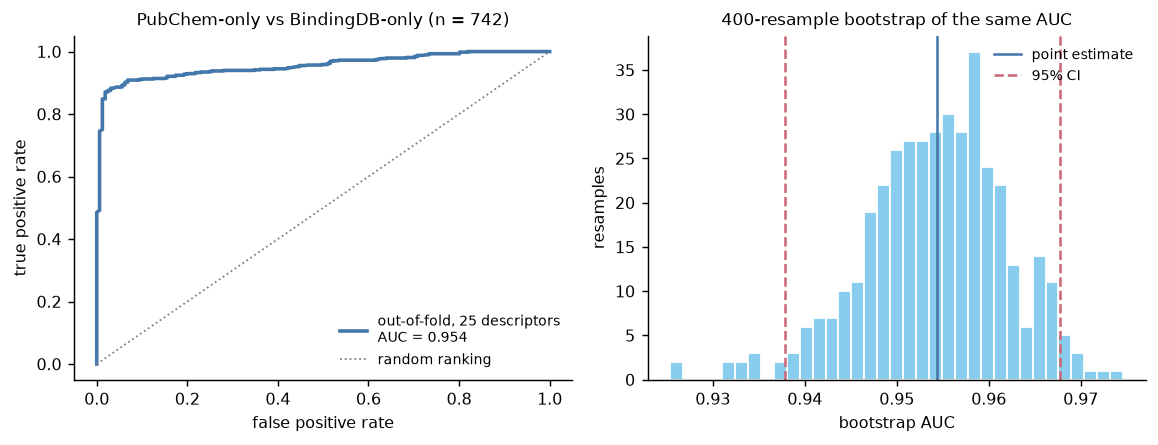

In [13]:
from sklearn.metrics import roc_curve as _roc

fig, axes = plt.subplots(1, 2, figsize=(9.0, 3.5))

f, t, _ = _roc(y, oof)
axes[0].plot(f, t, color="#4477aa", lw=2,
             label="out-of-fold, 25 descriptors\nAUC = %.3f" % auc_pooled)
axes[0].plot([0, 1], [0, 1], ls=":", color="grey", lw=1, label="random ranking")
axes[0].set_xlabel("false positive rate"); axes[0].set_ylabel("true positive rate")
axes[0].set_title("PubChem-only vs BindingDB-only (n = %d)" % len(y), fontsize=9.5)
axes[0].legend(frameon=False, fontsize=7.5, loc="lower right")

axes[1].hist(boot, bins=35, color="#88ccee", edgecolor="white")
for v, c, ls, lab in [(auc_pooled, "#4477aa", "-", "point estimate"),
                      (lo, "#cc6677", "--", "95% CI"), (hi, "#cc6677", "--", None)]:
    axes[1].axvline(v, color=c, ls=ls, lw=1.4, label=lab)
axes[1].set_xlabel("bootstrap AUC"); axes[1].set_ylabel("resamples")
axes[1].set_title("%d-resample bootstrap of the same AUC" % len(boot), fontsize=9.5)
axes[1].legend(frameon=False, fontsize=7.5)
fig.tight_layout()

<p class="caption"><b>Figure 3.</b> Left: the pooled out-of-fold ROC curve for predicting the
depositing database inside UI-Ref, AUC = 0.954. The curve rises almost vertically, so a large
fraction of PubChem-only molecules can be identified at a false positive rate below 0.2. Right:
the distribution of the AUC over 400 bootstrap resamples of the same out-of-fold predictions,
with the point estimate and the 2.5th and 97.5th percentiles marked. The interval
[0.938, 0.968] excludes 0.5 by a wide margin and reproduces the published
[0.939, 0.968] <sup class="c"><a href="#r1">[1]</a></sup>.</p>

In [14]:
yhat = (oof >= 0.5).astype(int)
cm = confusion_matrix(y, yhat, labels=[1, 0])          # rows/cols ordered PubChem, BindingDB
print(pd.DataFrame(cm, index=["true PubChem", "true BindingDB"],
                   columns=["pred PubChem", "pred BindingDB"]).to_string())
print("\nMCC      :", round(matthews_corrcoef(y, yhat), 4), " (table S5: 0.6999)")
print("accuracy :", round(accuracy_score(y, yhat), 4),
      " vs 0.783 for always predicting PubChem")

                pred PubChem  pred BindingDB
true PubChem             542              39
true BindingDB            37             124

MCC      : 0.6999  (table S5: 0.6999)
accuracy : 0.8976  vs 0.783 for always predicting PubChem


The confusion matrix at the default threshold of 0.5 gives an MCC of 0.700, matching the published
0.6999 <sup class="c"><a href="#r1">[1]</a></sup>. Note the contrast with accuracy: 0.898 against a
majority-class floor of 0.783, which sounds like a modest gain, whereas the MCC moves from 0.000 to
0.700. The same model, the same predictions, two very different impressions — exactly the reason
for the metric discipline of Section 3.

<div class="exercise">
<h4>Exercise 2</h4>
<p>Change <code>StratifiedKFold(n_splits=5, ...)</code> to <code>n_splits=10</code> and re-run the
cross-validation cell. The point estimate will barely move; the per-fold standard error will
change more. Explain which of the two quantities you would report, and why ten folds do not give a
more precise estimate of the same thing.</p>
</div>

## 5. The stronger version: predicting the source publication

**Why this analysis exists.** The depositing database is a coarse label: three resources, each
aggregating many laboratories. If provenance structure comes from the fact that individual papers
report congeneric series, then a finer provenance label — *which paper reported this molecule* —
should be even more predictable. This is a sharper test of the same hypothesis, and it is the
result the paper leans on when it argues that random cross-validation splits are inadmissible for
these data.

**What would refute it.** If source publication were not recoverable — AUCs near 0.5 — the
structure of Section 4 would be a property of database curation policy alone, and random splitting
would remain defensible as long as databases were kept apart.

The design is **one-versus-rest**: for each of the 12 largest contributing documents, build a
binary label that is 1 for the molecules from that document and 0 for all other 1,206 molecules,
and cross-validate a random forest on the 25 descriptors. Each task is severely imbalanced — the
largest document contributes 44 molecules, about 3.6% of the set — which is why the paper uses
3-fold stratification here, keeping at least a dozen positives in every held-out fold
<sup class="c"><a href="#r1">[1]</a></sup>.

In [15]:
top12 = ui["primary_document"].value_counts().head(12)
print("the 12 largest source documents and their molecule counts:")
print(top12.to_string())
print("\nshare of UI-Ref contributed by these 12 documents: "
      f"{100 * top12.sum() / len(ui):.1f}%")

the 12 largest source documents and their molecule counts:
primary_document
10.1016/j.bmcl.2019.02.032      44
10.1016/j.bmcl.2017.02.022      40
10.1016/j.ejmech.2018.06.065    40
10.1016/j.bmc.2018.07.003       37
10.1016/j.ejmech.2014.01.001    37
10.1016/j.ejmech.2017.03.070    34
CHEMBL1144858                   30
10.1016/j.ejmech.2010.08.015    29
10.1016/j.ejmech.2013.03.016    28
10.1016/j.bmc.2014.05.057       27
10.1016/j.ejmech.2013.10.012    26
10.1021/acs.jmedchem.2c01799    25

share of UI-Ref contributed by these 12 documents: 32.6%


In [16]:
cv3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
X_all = ui[DESC].values

doc_auc = {}
for doc in top12.index:
    yb = (ui["primary_document"] == doc).astype(int).values
    sb = cross_val_predict(RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                                  random_state=RANDOM_STATE, n_jobs=-1),
                           X_all, yb, cv=cv3, method="predict_proba", n_jobs=1)[:, 1]
    doc_auc[doc] = roc_auc_score(yb, sb)

doc_tab = (pd.DataFrame({"n_molecules": top12, "AUC_recomputed": pd.Series(doc_auc)})
             .sort_values("AUC_recomputed", ascending=False).round(4))
print(doc_tab.to_string())
med = float(np.median(list(doc_auc.values())))
print(f"\nmedian one-vs-rest AUC: {med:.4f}"
      f"   (range {min(doc_auc.values()):.4f} - {max(doc_auc.values()):.4f})")

                              n_molecules  AUC_recomputed
CHEMBL1144858                          30          0.9993
10.1021/acs.jmedchem.2c01799           25          0.9992
10.1016/j.bmc.2018.07.003              37          0.9990
10.1016/j.bmc.2014.05.057              27          0.9976
10.1016/j.ejmech.2018.06.065           40          0.9968
10.1016/j.bmcl.2017.02.022             40          0.9940
10.1016/j.ejmech.2013.03.016           28          0.9927
10.1016/j.ejmech.2017.03.070           34          0.9916
10.1016/j.ejmech.2010.08.015           29          0.9880
10.1016/j.ejmech.2013.10.012           26          0.9870
10.1016/j.ejmech.2014.01.001           37          0.9668
10.1016/j.bmcl.2019.02.032             44          0.9418

median one-vs-rest AUC: 0.9934   (range 0.9418 - 0.9993)


The median one-versus-rest AUC over the twelve documents is **0.9934**, with a range of 0.942 to
0.999. Eight of the twelve exceed 0.99: given a molecule and 25 ordinary physicochemical
properties, a random forest identifies the publication it came from almost without error.

Compare with the paper. It reports a median of 0.997 (range 0.962–1.000) on descriptors
<sup class="c"><a href="#r1">[1]</a></sup>, and supplementary table S5 lists the same twelve
documents. Our median is 0.9934 rather than 0.997. The difference is not an error on either side:
the paper states explicitly that re-running its frozen scripts under current package versions
returns 0.9934 for this quantity, a change of $-0.0036$ attributable to the RDKit version
<sup class="c"><a href="#r1">[1]</a></sup>. Our independent re-implementation lands on the same
re-run value. The next cell puts the two side by side so you can see which documents moved.

In [17]:
s5 = load_table("results/tables/tableS5_provenance_floor.csv")
pub = (s5[(s5.subset == "all 1218 one-vs-rest") & (s5.features == "25 descriptors")]
       [["task", "auc"]].copy())
pub["document"] = pub["task"].str.replace("document ", "", regex=False)
cmp_doc = (doc_tab.join(pub.set_index("document")["auc"].rename("AUC_published"))
           .assign(difference=lambda d: (d.AUC_recomputed - d.AUC_published).round(4)))
print(cmp_doc[["n_molecules", "AUC_published", "AUC_recomputed", "difference"]].to_string())
print(f"\npublished median: {cmp_doc.AUC_published.median():.4f}"
      f" | recomputed median: {cmp_doc.AUC_recomputed.median():.4f}")

                              n_molecules  AUC_published  AUC_recomputed  difference
CHEMBL1144858                          30       0.999242          0.9993      0.0001
10.1021/acs.jmedchem.2c01799           25       0.999246          0.9992     -0.0000
10.1016/j.bmc.2018.07.003              37       0.999142          0.9990     -0.0001
10.1016/j.bmc.2014.05.057              27       0.997232          0.9976      0.0004
10.1016/j.ejmech.2018.06.065           40       0.998642          0.9968     -0.0018
10.1016/j.bmcl.2017.02.022             40       0.996711          0.9940     -0.0027
10.1016/j.ejmech.2013.03.016           28       0.996849          0.9927     -0.0041
10.1016/j.ejmech.2017.03.070           34       0.991082          0.9916      0.0005
10.1016/j.ejmech.2010.08.015           29       0.963487          0.9880      0.0245
10.1016/j.ejmech.2013.10.012           26       0.981043          0.9870      0.0060
10.1016/j.ejmech.2014.01.001           37       0.965970         

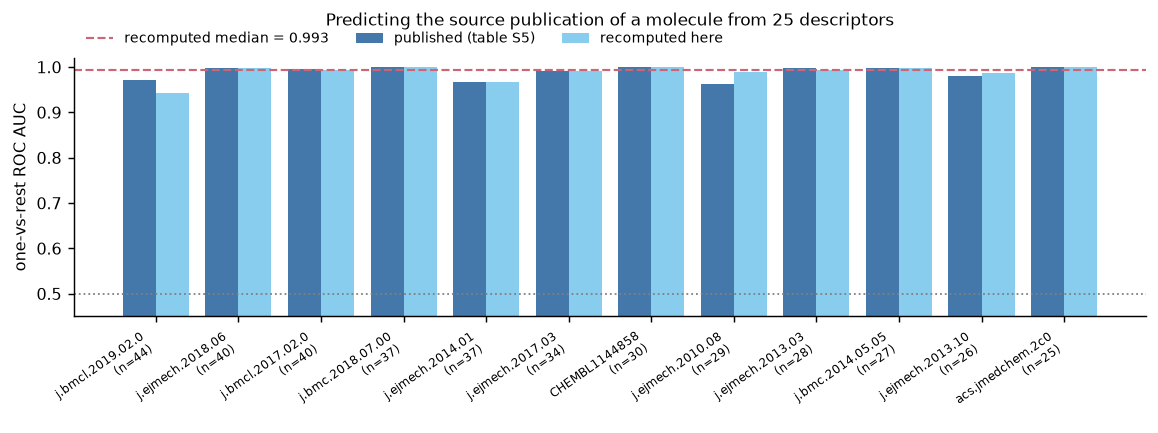

In [18]:
fig, ax = plt.subplots(figsize=(9.0, 3.4))
o = cmp_doc.sort_values("n_molecules", ascending=False)
xs = np.arange(len(o))
ax.bar(xs - 0.2, o.AUC_published, width=0.4, color="#4477aa", label="published (table S5)")
ax.bar(xs + 0.2, o.AUC_recomputed, width=0.4, color="#88ccee", label="recomputed here")
ax.axhline(0.5, ls=":", color="grey", lw=1)
ax.axhline(float(np.median(list(doc_auc.values()))), ls="--", color="#cc6677", lw=1.2,
           label="recomputed median = %.3f" % np.median(list(doc_auc.values())))
ax.set_xticks(xs)
ax.set_xticklabels([d.split("/")[-1][:16] + "\n(n=%d)" % n
                    for d, n in zip(o.index, o.n_molecules)], fontsize=6.5, rotation=35,
                   ha="right")
ax.set_ylim(0.45, 1.02); ax.set_ylabel("one-vs-rest ROC AUC")
ax.set_title("Predicting the source publication of a molecule from 25 descriptors",
             fontsize=9.5, pad=18)
ax.legend(frameon=False, fontsize=7.5, ncol=3, loc="lower left", bbox_to_anchor=(0.0, 1.0))
fig.tight_layout()

<p class="caption"><b>Figure 4.</b> One-versus-rest ROC AUC for identifying the source publication
of a UI-Ref molecule from its 25 descriptors, for the twelve largest documents, ordered by size.
Published values from supplementary table S5 <sup class="c"><a href="#r1">[1]</a></sup> in dark
blue, our recomputation in light blue; the dotted line marks random ranking and the dashed line the
recomputed median of 0.993. Ten of the twelve differ between runs by less than 0.01; the largest
discrepancy is the 44-molecule document at the left, where the small positive class makes the
3-fold estimate itself unstable.</p>

The mechanism is the one the paper names: a medicinal-chemistry paper reports a congeneric series
built on one scaffold with a few substituent variations, so its molecules share size, polarity and
ring composition to a degree that 25 descriptors capture easily
<sup class="c"><a href="#r1">[1]</a></sup>. The corollary for validation is what makes the number
consequential: if publication identity is recoverable at AUC $\approx$ 0.99, any split that puts
molecules from one publication on both sides of a train/test boundary is testing the model on
molecules it has already seen in all but name.

<div class="box bridge">
<h4>Forward link</h4>
<p>Notebook 3 takes this result and turns it into a validation rule: group the cross-validation
folds by source document, so that a publication is never split across the boundary. The AUC drop
that follows is the measurement of how much of the original performance was publication
recognition.</p>
</div>

## 6. What 0.954 is, and what it is not

This is the most important section of the notebook, and the one most likely to be skipped. We have
two numbers — 0.954 for the database and 0.993 for the publication — and an obvious temptation:
use them as a bar. If a cross-collection comparison scores below 0.954, declare it
"provenance-level" and dismiss it; if above, declare it real. The paper explicitly refuses to do
this, and the refusal is worth understanding in detail, because the reasoning generalises to every
comparison of two performance numbers you will ever make.

### 6.1 What it is: an empirical reference scale

The paper's own words are that the two values "provide an empirical reference scale for interpreting
the cross-library classifiers reported below, but they are not transferable thresholds"
<sup class="c"><a href="#r1">[1]</a></sup>. A reference scale is a statement of magnitude: in this
corpus, with this representation, labels with no biochemical content are separable at
AUC $\approx$ 0.95–0.99. It establishes that "AUC 0.95" is not by itself evidence of chemistry.

### 6.2 What it is not: a decision threshold

An AUC is not a property of a model. It is a property of a model **and** a population **and** a
validation scheme, and changing any of the three moves the number for reasons unrelated to model
quality. The two tasks differ in all three — the paper names class priors, sample size and
validation structure <sup class="c"><a href="#r1">[1]</a></sup>. Let us quantify them.

In [19]:
clue = load_table("data/processed/collection_CLUE.parquet")
overlap = set(ui["inchikey"]) & set(clue["inchikey"])
n_clue = len(clue) - len(overlap)          # CLUE molecules that are not already in UI-Ref

tasks = pd.DataFrame(
    [{"task": "provenance (Section 4)", "positives": int(y.sum()), "negatives": int((1 - y).sum()),
      "n": len(y), "folds": "stratified 5-fold, random",
      "unit": "molecule, within one collection"},
     {"task": "provenance (Section 5)", "positives": int(top12.iloc[0]),
      "negatives": len(ui) - int(top12.iloc[0]), "n": len(ui),
      "folds": "stratified 3-fold, random", "unit": "molecule, within one collection"},
     {"task": "UI-Ref vs CLUE (Notebook 3)", "positives": len(ui), "negatives": n_clue,
      "n": len(ui) + n_clue, "folds": "document-grouped 5-fold",
      "unit": "molecule, across two collections"}])
tasks["prevalence"] = (tasks.positives / tasks.n).round(3)
print(tasks[["task", "n", "positives", "negatives", "prevalence", "folds", "unit"]].to_string(index=False))

                       task    n  positives  negatives  prevalence                     folds                             unit
     provenance (Section 4)  742        581        161       0.783 stratified 5-fold, random  molecule, within one collection
     provenance (Section 5) 1218         44       1174       0.036 stratified 3-fold, random  molecule, within one collection
UI-Ref vs CLUE (Notebook 3) 5635       1218       4417       0.216   document-grouped 5-fold molecule, across two collections


Read the table as three reasons why the numbers are not commensurable.

**Different populations.** The provenance task concerns 742 urease-assayed molecules; the
cross-collection task concerns 5,635 molecules of which 4,417 are clinical compounds from the Drug
Repurposing Hub <sup class="c"><a href="#r16">[16]</a></sup> never tested against urease. AUC is a
probability over positive–negative pairs drawn from a particular population, so the two numbers
answer different questions. There is no population on which both are defined, hence no quantity of
which 0.954 and, say, 0.766 are two estimates.

**Different class priors.** Prevalence is 0.783 in the provenance task and 0.216 in the
cross-collection task. AUC is prior-independent in the narrow sense that duplicating negatives
leaves it unchanged, but task *difficulty* is not: with a 3.6% positive class, as in the publication
task, a handful of molecules determines the estimate and the sampling variance of the AUC is far
larger than for a balanced task of the same size. Comparing point estimates whose sampling
distributions have different widths is a category error.

**Different validation structure.** The provenance AUC comes from random stratified folds, the
corrected cross-collection AUC from document-grouped folds. These estimate different quantities:
performance on a molecule from a publication the model *has* seen, against one from a publication it
has not. Notebook 3 shows that gap is worth about 0.19 AUC here, so comparing the two is comparing
an optimistic estimator with a conservative one.

<div class="box warn">
<h4>The general rule</h4>
<p>Two AUCs can be compared only when they are estimated on the same molecules, by the same
validation scheme, for the same label. When both models score the same test set, there are proper
tools for the comparison: a paired bootstrap over the shared test molecules, or the DeLong test for
two correlated ROC curves <sup class="c"><a href="#r17">[17]</a></sup>. When the test sets differ,
no test applies, and the difference of the point estimates is not an effect size. "Our AUC is
higher than theirs" is, in that situation, a sentence with no statistical content. The QSAR
literature has made this argument about correlation coefficients for two decades, in the same
terms <sup class="c"><a href="#r14">[14]</a></sup>: a validation statistic is interpretable only
together with the design that produced it.</p>
</div>

### 6.3 What the paper does instead

Having refused the threshold, the paper still needs an answer to "is the residual cross-collection
separation more than provenance?". Its solution is to build the comparison **inside** the task: four
null models, each fitted with the same estimator, the same document-grouped folds and the same seed
as the observed model, on the same molecules <sup class="c"><a href="#r1">[1]</a></sup>. Because the
nulls score the same test set, the paired bootstrap and the DeLong test become legitimate.

The most informative null replaces every descriptor with five features describing only a molecule's
relative position within its own source library — its scaffold frequency and fingerprint-neighbourhood
density there — encoding no absolute chemistry. Under the corrected design it reaches AUC 0.9947,
0.9956 and 0.9957 against CLUE, COCONUT and DSSTox, exceeding the observed models by 0.154–0.234
with DeLong $Z$ between $-20.1$ and $-24.6$ <sup class="c"><a href="#r1">[1]</a></sup>: library
assembly alone beats the full 25-descriptor representation on the task the descriptors were
supposed to be good at.

<div class="box bridge">
<h4>Forward link</h4>
<p>Notebook 4 builds these nulls. The reason it can make a quantitative claim where this notebook
cannot is exactly the one given above: its comparison is within a task, not across tasks.</p>
</div>

<div class="box key">
<h4>Key idea</h4>
<p>The provenance experiment establishes a <em>possibility</em>, not a bound. It shows that
descriptor-based separation at AUC 0.95 can be produced by a label with no biochemical content on
these very molecules. It does not license subtracting 0.954 from anything, nor declaring any
particular cross-collection result "explained by provenance". That requires a null constructed
inside the same task.</p>
</div>

## 7. An information-theoretic view of the same structure

**Why this analysis exists.** The classifier of Sections 4 and 5 shows that provenance is
*predictable from chemistry*. A second, complementary question is how the provenance variables
relate to one another: if source publication also determines the assay organism, the assay
endpoint and the chemical series, then grouping folds by publication does not isolate a
"publication effect" — it changes everything at once. Classification cannot answer that, because
there is no model involved. Information theory can, because it measures dependence between two
labellings directly.

**What would refute the paper's reading.** If document and organism were close to independent, the
paper could not claim that the confounding is composite, and treating organism as a separately
adjustable factor would be defensible. The quantity below would then be close to 1.

### 7.1 Entropy

Shannon's entropy measures how uncertain a labelling is <sup class="c"><a href="#r8">[8]</a></sup>.
For a discrete variable $Y$ taking value $k$ with probability $p_k$,

$$H(Y) = -\sum_k p_k \log_2 p_k \quad \text{bits.}$$

It is $0$ when one outcome is certain and $\log_2 K$ when $K$ outcomes are equiprobable: the average
number of yes/no questions needed to identify the value. With seven assay organisms recorded, the
organism entropy cannot exceed $\log_2 7 = 2.807$ bits, and is lower because
*Canavalia ensiformis* accounts for roughly half the molecules.

### 7.2 Conditional entropy

If we are told the source publication first, how much uncertainty about the organism remains? That
is the **conditional entropy**, the entropy of $Y$ within each group of $X$, averaged over groups:

$$H(Y \mid X) = \sum_x \Pr(X = x)\, H(Y \mid X = x).$$

Dividing by $H(Y)$ makes it a unitless fraction between 0 and 1:

$$\frac{H(Y \mid X)}{H(Y)} = \text{fraction of the uncertainty in } Y \text{ that survives knowing } X .$$

A value of 1 means $X$ tells you nothing about $Y$; a value of 0 means $X$ determines $Y$
completely. Note that the logarithm base cancels in the ratio, so the normalised quantity is the
same whether you work in bits or in nats — a useful check when comparing with a table that reports
raw entropies in different units.

In [20]:
def entropy_bits(labels):
    """Shannon entropy in bits of an array of categorical labels."""
    p = pd.Series(labels).value_counts(normalize=True).values
    return float(-(p * np.log2(p)).sum())

def conditional_entropy_bits(y_lab, x_lab):
    """H(Y | X) in bits: entropy of Y inside each group of X, weighted by group size."""
    d = pd.DataFrame({"y": y_lab, "x": x_lab})
    return float(sum(len(g) / len(d) * entropy_bits(g["y"].values)
                     for _, g in d.groupby("x", observed=True)))

rows = []
for name, col in [("assay organism", "primary_organism"),
                  ("scaffold class", "grp_scaffold"),
                  ("endpoint type", "dominant_endpoint")]:
    HY   = entropy_bits(ui[col].values)
    HYgX = conditional_entropy_bits(ui[col].values, ui["grp_document"].values)
    rows.append((name, ui[col].nunique(), round(HY, 4), round(HYgX, 4),
                 round(HYgX / HY, 4), round(1 - HYgX / HY, 4)))
ent = pd.DataFrame(rows, columns=["factor Y", "levels", "H(Y) bits", "H(Y|document) bits",
                                  "normalised", "explained by document"])
print(ent.to_string(index=False))
print("\ndocument grouping key:", ui["grp_document"].nunique(),
      "groups over", len(ui), "molecules")

      factor Y  levels  H(Y) bits  H(Y|document) bits  normalised  explained by document
assay organism       7     1.9247              0.0308      0.0160                 0.9840
scaffold class     214     5.8636              1.0680      0.1821                 0.8179
 endpoint type       4     0.5989              0.0846      0.1412                 0.8588

document grouping key: 153 groups over 1218 molecules


The normalised conditional entropy of assay organism given source document is **0.0160**, so the
source publication accounts for 98.4% of the variation in organism. The corresponding values are
0.1821 for scaffold class — Bemis–Murcko frameworks, the scaffold definition of Notebook 1
<sup class="c"><a href="#r11">[11]</a></sup> — and 0.1412 for endpoint type, i.e. 81.8% and 85.9%
explained. All three
reproduce the published values of 0.016, 0.182 and 0.141 exactly
<sup class="c"><a href="#r1">[1]</a></sup>.

Two details silently change this number. The grouping key `grp_document` has 153 levels although
only 77 named documents exist, because the 76 molecules with no document identifier each form a
singleton group — conservative for validation, but it inflates the group count; restricting to the
1,142 documented molecules gives 0.0177, 0.1985 and 0.1456 instead, and the paper reports both
variants. And the published table quotes raw entropies in nats ($H = 1.3341$ for organism) where our
cell prints bits ($H = 1.9247$); since $1.9247 \times \ln 2 = 1.3341$, these are the same numbers in
different units and the normalised ratio is unaffected.

The consequence is structural, not statistical. Only three of the 77 named documents report assays
against more than one organism, and those three contain 49 molecules
<sup class="c"><a href="#r1">[1]</a></sup>. There is therefore almost no within-publication
variation in organism to exploit: any analysis that groups by document has also, unavoidably,
grouped by organism, laboratory and chemical series. This is why the paper describes the
confounding as *composite* and declines to report an isolated effect of provenance independent of
chemistry <sup class="c"><a href="#r1">[1]</a></sup>.

documents among the twelve largest that report more than one organism: 1


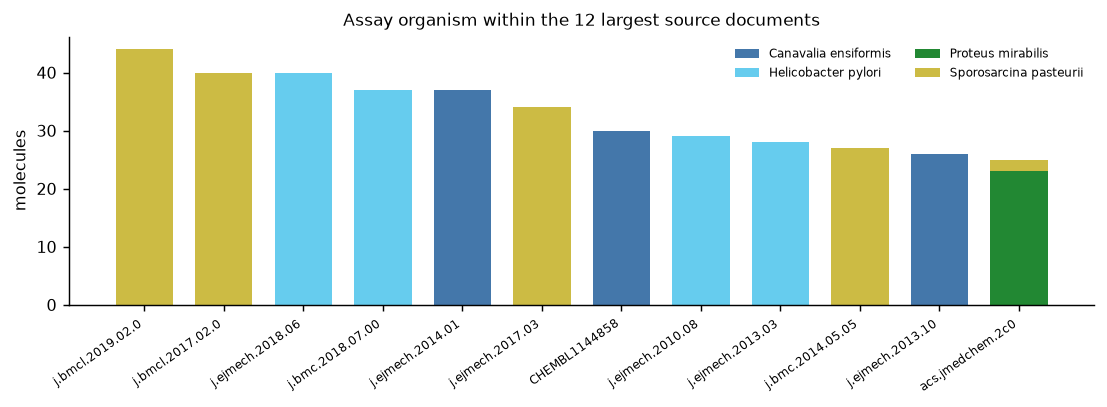

In [21]:
doc12 = list(top12.index)
comp = (ui[ui.primary_document.isin(doc12)]
        .pivot_table(index="primary_document", columns="primary_organism",
                     values="row_id", aggfunc="count")
        .reindex(doc12).fillna(0))
fig, ax = plt.subplots(figsize=(8.6, 3.2))
bottom = np.zeros(len(comp))
palette = ["#4477aa", "#66ccee", "#228833", "#ccbb44", "#ee6677", "#aa3377", "#bbbbbb"]
for k, org in enumerate(comp.columns):
    ax.bar(np.arange(len(comp)), comp[org].values, bottom=bottom, width=0.72,
           color=palette[k % len(palette)], label=org)
    bottom += comp[org].values
ax.set_xticks(np.arange(len(comp)))
ax.set_xticklabels([d.split("/")[-1][:16] for d in comp.index], fontsize=6.5,
                   rotation=35, ha="right")
ax.set_ylabel("molecules")
ax.set_title("Assay organism within the 12 largest source documents", fontsize=9.5)
print("documents among the twelve largest that report more than one organism:",
      int(((comp > 0).sum(axis=1) > 1).sum()))
ax.legend(frameon=False, fontsize=6.8, ncol=2)
fig.tight_layout()

<p class="caption"><b>Figure 5.</b> Organism composition of the twelve largest source documents in
UI-Ref. Eleven of the twelve bars are a single colour: those publications report assays against
exactly one organism. The twelfth splits 23 molecules against <em>Proteus mirabilis</em> and 2
against <em>Sporosarcina pasteurii</em>, and is one of only three documents in the whole set that
report more than one organism <sup class="c"><a href="#r1">[1]</a></sup>. This is the visual form of
the normalised conditional entropy of 0.016: folds grouped by document are also, unavoidably, folds
grouped by organism.</p>

### 7.3 Mutual information and its adjusted form

**The problem it solves.** Conditional entropy compares a labelling with another labelling. We also
want to compare a labelling with a *clustering* obtained from chemistry alone — if we group
molecules by structural similarity, which label do the groups correspond to?

**Mutual information** is the reduction in uncertainty about $Y$ from knowing $X$:

$$I(X; Y) = H(Y) - H(Y \mid X) = \sum_{x,y} p(x,y) \log_2 \frac{p(x,y)}{p(x)\,p(y)} \;\ge\; 0,$$

symmetric in its arguments and zero exactly when $X$ and $Y$ are independent. Used raw to compare a
clustering with a label, it has an awkward property: it increases with the number of clusters even
for random clusterings, because fine partitions resemble any labelling by chance. The **adjusted
mutual information** corrects for that by subtracting the expectation under a random permutation
model and rescaling <sup class="c"><a href="#r9">[9]</a></sup>:

$$\mathrm{AMI}(U, V) = \frac{I(U; V) - \mathbb{E}[I(U; V)]}{\tfrac{1}{2}\left(H(U) + H(V)\right) - \mathbb{E}[I(U; V)]},$$

which is 0 for a random clustering of any granularity and 1 for perfect agreement, making AMI
comparable across different numbers of clusters.

The analysis below clusters molecules on structure alone — 2,048-bit ECFP4 fingerprints
<sup class="c"><a href="#r10">[10]</a></sup>, $k$-means — over UI-Ref plus an equal-sized random
sample of each external collection, then asks which label the clusters recover. The paper uses
$k$-means on a UMAP embedding and Butina clustering at Tanimoto 0.4
<sup class="c"><a href="#r1">[1]</a></sup>; we cluster the fingerprint matrix directly, since UMAP
is not a dependency here and the point is the comparison between labels, not the algorithm.

In [22]:
from rdkit import Chem, RDLogger, DataStructs
from rdkit.Chem import rdFingerprintGenerator
RDLogger.DisableLog("rdApp.*")
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_mutual_info_score, mutual_info_score

coco = load_table("data/processed/collection_COCONUT.parquet")
dss  = load_table("data/processed/collection_DSSTox.parquet")

parts = [ui.assign(collection="UI-Ref")[["smiles_std", "collection"]]]
for nm, d in [("CLUE", clue), ("COCONUT", coco), ("DSSTox", dss)]:
    parts.append(d.sample(len(ui), random_state=RANDOM_STATE)
                  .assign(collection=nm)[["smiles_std", "collection"]])
pool = pd.concat(parts, ignore_index=True)

gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)   # ECFP4
fps, keep = [], []
for smi in pool["smiles_std"]:
    m = Chem.MolFromSmiles(smi)
    keep.append(m is not None)
    if m is not None:
        fps.append(gen.GetFingerprintAsNumPy(m))
FP = np.asarray(fps, dtype=np.float32)
pool = pool[keep].reset_index(drop=True)
print("pooled molecules fingerprinted:", FP.shape[0], "x", FP.shape[1], "bits")
print(pool["collection"].value_counts().to_string())

pooled molecules fingerprinted: 4872 x 2048 bits
collection
UI-Ref     1218
CLUE       1218
COCONUT    1218
DSSTox     1218


In [23]:
km = KMeans(n_clusters=20, n_init=4, random_state=RANDOM_STATE).fit(FP)
pool["cluster"] = km.labels_

ui_rows = pool["collection"] == "UI-Ref"
ui_pool = pool[ui_rows].copy()
assert len(ui_pool) == len(ui), "a UI-Ref SMILES failed to parse; row alignment broken"
ui_pool["document"] = ui["primary_document"].values
ui_pool["organism"] = ui["primary_organism"].values
documented = ui_pool[ui_pool["document"].notna()]

ami = {("collection", "pooled k=20"):
           adjusted_mutual_info_score(pool["collection"], pool["cluster"]),
       ("source document", "pooled k=20"):
           adjusted_mutual_info_score(documented["document"], documented["cluster"]),
       ("assay organism", "pooled k=20"):
           adjusted_mutual_info_score(ui_pool["organism"], ui_pool["cluster"])}

# a second clustering, inside UI-Ref only, at two granularities
for k in [20, 77]:
    lab = KMeans(n_clusters=k, n_init=4, random_state=RANDOM_STATE).fit_predict(FP[ui_rows.values])
    ui_pool["cl_k"] = lab
    dd = ui_pool[ui_pool["document"].notna()]
    ami[("source document", "UI-Ref k=%d" % k)] = adjusted_mutual_info_score(dd["document"], dd["cl_k"])
    ami[("assay organism", "UI-Ref k=%d" % k)] = adjusted_mutual_info_score(ui_pool["organism"], ui_pool["cl_k"])

print(pd.Series(ami).round(4).to_string())
mi_bits = mutual_info_score(pool["collection"], pool["cluster"]) / np.log(2)
print(f"\nraw mutual information, clusters vs collection: {mi_bits:.4f} bits")

collection       pooled k=20    0.1875
source document  pooled k=20    0.5480
assay organism   pooled k=20    0.3034
source document  UI-Ref k=20    0.6521
assay organism   UI-Ref k=20    0.3340
source document  UI-Ref k=77    0.7798
assay organism   UI-Ref k=77    0.3554

raw mutual information, clusters vs collection: 0.5325 bits


The adjusted mutual information between the structural clusters and **collection membership** is
**0.1875**. Between the same kind of clusters and **source document** it is 0.548 for the pooled
clustering and rises to 0.652 and 0.780 when UI-Ref is clustered on its own at $k = 20$ and
$k = 77$. Assay organism sits in between, at 0.30 to 0.36.

The published ranges are 0.125–0.187 for collection, 0.385–0.814 for source document and
0.220–0.396 for assay organism, obtained over several clustering algorithms and granularities
<sup class="c"><a href="#r1">[1]</a></sup>. Our document and organism values fall inside the
corresponding published ranges; the collection value, 0.1875, sits a hair above the published upper
bound of 0.187, which is what you should expect from clustering ECFP4 bits directly instead of the
paper's k-means-on-UMAP and Butina clustering. The ordering — document $\gg$ organism $>$
collection — is reproduced, and that ordering, not the third decimal, is the result. The
paper's conclusion follows: much of the apparent organisation of this chemical space is associated
with the bibliographic origin of the molecules rather than with collection identity
<sup class="c"><a href="#r1">[1]</a></sup>.

Note also the contrast between the adjusted and the raw quantity printed at the end of the cell.
The raw mutual information with collection is a number of bits whose magnitude depends on how many
clusters we asked for; the AMI is the same information expressed on a scale where a random
clustering scores 0 regardless of $k$. When you see "mutual information" in a paper comparing
clusterings, check which of the two is meant.

<div class="exercise">
<h4>Exercise 3</h4>
<p>Change <code>n_clusters=20</code> in the pooled $k$-means to 5 and then to 100, and watch the
raw mutual information and the AMI. One of them grows monotonically with $k$ and the other does
not. Which, and why does that make AMI the comparable quantity?</p>
</div>

## 8. Which descriptors carry the provenance signal?

**Why this analysis exists.** If the signal were carried by one exotic descriptor, a comparison
could be protected by dropping it. If it is carried by the ordinary properties every
cross-collection comparison relies on — size, lipophilicity, saturation — no feature-selection fix
exists and a design-level control is required instead. Equivalently: if the provenance classifier
depended on descriptors that played no role in the cross-collection models, the two signals would
be separable and the provenance result a curiosity rather than a confound.

**Permutation importance** answers the question with no model-specific machinery
<sup class="c"><a href="#r15">[15]</a></sup>. Fit the model once, measure its score on held-out
data, then randomly shuffle the values of one feature across the held-out molecules and measure the
score again. Shuffling destroys any relationship between that feature and the label while leaving
its marginal distribution intact, so the drop in score

$$\mathrm{imp}_j = \mathrm{AUC}(\text{original}) - \overline{\mathrm{AUC}(\text{feature } j \text{ shuffled})}$$

is the amount of performance that depended on feature $j$. Repeating the shuffle several times
gives a standard deviation. The paper uses TreeSHAP instead, which decomposes each individual
prediction into additive per-feature contributions and is more informative but also more
machinery <sup class="c"><a href="#r12">[12]</a></sup>; for the question "which descriptors carry
the signal", permutation importance is sufficient and is available in scikit-learn without extra
dependencies.

In [24]:
from sklearn.inspection import permutation_importance

model = RandomForestClassifier(n_estimators=300, class_weight="balanced",
                               random_state=RANDOM_STATE, n_jobs=-1).fit(Xtr, ytr)
base_auc = roc_auc_score(yte, model.predict_proba(Xte)[:, 1])

pi = permutation_importance(model, Xte, yte, scoring="roc_auc", n_repeats=10,
                            random_state=RANDOM_STATE)        # serial: 10 shuffles x 25 features
imp = (pd.DataFrame({"descriptor": DESC, "AUC_drop": pi.importances_mean,
                     "SD": pi.importances_std})
       .sort_values("AUC_drop", ascending=False).reset_index(drop=True))
imp["rank"] = imp.index + 1
print("held-out AUC before any shuffling:", round(base_auc, 4))
print(imp.head(10).round(4).to_string(index=False))

held-out AUC before any shuffling: 0.9526
             descriptor  AUC_drop     SD  rank
                   LogP    0.0263 0.0047     1
                  MolMR    0.0080 0.0064     2
           FractionCSP3    0.0079 0.0040     3
 NumAromaticCarbocycles    0.0062 0.0011     4
                    HBA    0.0054 0.0025     5
NumAromaticHeterocycles    0.0040 0.0021     6
               NumAtoms    0.0039 0.0014     7
                   TPSA    0.0035 0.0029     8
          NumHeavyAtoms    0.0031 0.0017     9
          NumAmideBonds    0.0023 0.0014    10


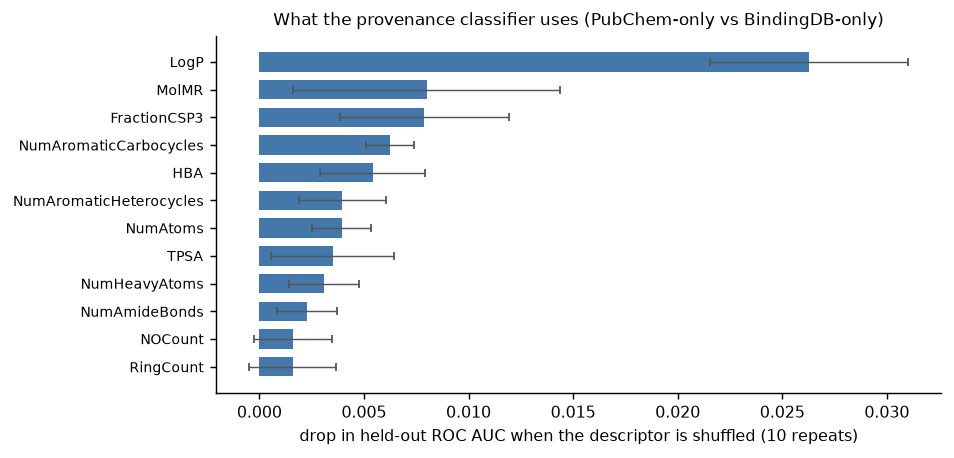

In [25]:
fig, ax = plt.subplots(figsize=(7.4, 3.6))
top = imp.head(12).iloc[::-1]
ax.barh(np.arange(len(top)), top.AUC_drop, xerr=top.SD, color="#4477aa",
        error_kw=dict(lw=0.8, capsize=2, ecolor="#555555"), height=0.7)
ax.set_yticks(np.arange(len(top)))
ax.set_yticklabels(top.descriptor, fontsize=7.5)
ax.set_xlabel("drop in held-out ROC AUC when the descriptor is shuffled (10 repeats)")
ax.set_title("What the provenance classifier uses (PubChem-only vs BindingDB-only)", fontsize=9.5)
fig.tight_layout()

<p class="caption"><b>Figure 6.</b> Permutation importance of the 12 highest-ranked descriptors for
predicting the depositing database: the loss of held-out ROC AUC when one descriptor is shuffled,
over 10 shuffles, with standard deviations as error bars. cLogP dominates at a drop of 0.026, more
than three times the next descriptor, followed by molar refractivity and sp3 fraction. The held-out
AUC before shuffling is 0.953.</p>

The ranking reproduces the paper's finding about this classifier: "the provenance classifier itself
relied primarily on cLogP and molar refractivity" <sup class="c"><a href="#r1">[1]</a></sup> — our
first two permutation ranks are exactly those descriptors. The paper adds that FractionCSP3 fell to
rank 6 in its SHAP analysis of the provenance model, at 5.0–6.5% of the total attribution, whereas
it ranked first or second in the cross-collection models
<sup class="c"><a href="#r1">[1]</a></sup>. Our permutation ranking places it third. The two methods
measure different things — SHAP apportions each prediction, permutation importance measures the
performance cost of removing information — and with correlated descriptors they routinely differ by
a few ranks. The interpretively important part is identical: the provenance signal rides on generic
physicochemical bulk properties, not on anything resembling urease pharmacology.

<div class="box warn">
<h4>Correlated features defeat all single-feature attributions</h4>
<p>MolWt, ExactMolWt, HeavyAtomMolWt, NumAtoms and NumHeavyAtoms are near-duplicates of one
another in this table. Shuffle any one of them and the forest simply reads the same information
from its twins, so each appears unimportant — the permutation importance of a feature is the
performance that depends on it <em>given that the others remain</em>, not its intrinsic
informativeness. Never read a low permutation importance as evidence that a property does not
matter, and never prune features on that basis without checking the correlation structure
first.</p>
</div>

The practical consequence closes the loop with Section 1: the descriptors that carry provenance are
the descriptors every cross-collection comparison uses, so there is no subset to discard and the
remedy must operate at the level of the design — match the collections on those properties, group
the folds so a publication is never split, and compare against a null built inside the same task.
That is best practice for QSAR validation stated in general terms
<sup class="c"><a href="#r13">[13]</a></sup>, and it is the content of the next two notebooks.

## 9. Summary

You should be able to explain the following without notes.

- **The design.** Predicting provenance *inside* one target-focused collection holds target
  chemistry constant, so any signal the model finds is a property of how records were made. This is
  what makes the experiment interpretable; running it across collections would prove nothing.
- **The prediction and its fate.** If descriptor separation tracked target chemistry, provenance
  inside UI-Ref should have been unpredictable. We obtained AUC 0.9544 [0.938, 0.968] for the
  depositing database and a median 0.9934 for the source publication. The prediction failed.
- **Random forests.** Bagged decision trees with feature subsampling at every split; the bootstrap
  and the feature subsets decorrelate the trees, lowering the variance floor that averaging alone
  cannot reach. Suited to tabular descriptors because threshold splits are scale-invariant.
- **Metrics.** All are functions of TP, FP, FN, TN. AUC is the probability that a random positive
  outranks a random negative, hence threshold-free. MCC uses all four cells and cannot be inflated
  by neglecting the minority class. Accuracy has a majority-class floor — here 78.3%.
- **Cross-validation.** $k$-fold estimates the performance of a *procedure* on new data *from the
  same population*. The across-fold standard error is a dispersion diagnostic biased downward by
  shared training data; report the bootstrap percentile interval over out-of-fold predictions.
- **The reference scale.** 0.954 and 0.997 state a magnitude: meaningless labels are separable at
  that level on these molecules with these descriptors. They are not thresholds, because the
  provenance and cross-collection tasks differ in population, class prior and validation structure,
  and an AUC is a property of all three. Comparisons of AUC require a shared test set; the paper
  therefore builds nulls inside the task instead.
- **The information-theoretic view.** $H(\text{organism}\mid\text{document})/H(\text{organism})
  = 0.016$, and AMI with structural clusters is 0.19 for collection against 0.55–0.78 for document.
  The confounding is composite and not decomposable into separable factors.
- **The attribution.** The signal is carried by cLogP, molar refractivity and sp3 fraction — the
  properties every cross-collection comparison relies on — so the remedy is a design control, not
  feature selection.

## 10. Self-assessment

<details><summary>Q1. Why does the provenance experiment have to be run inside a single
target-focused collection rather than between two collections?</summary>
To hold target chemistry constant. Inside UI-Ref every molecule was reported in a urease assay, so
"depositing database" cannot carry biochemical meaning and any recovered signal must come from how
the record was made. Across two collections, chemistry and provenance vary together.</details>

<details><summary>Q2. A colleague reports a classifier with 97% accuracy on a task where 96% of
molecules are negative. What do you ask for?</summary>
The confusion matrix, and MCC or balanced accuracy from it: always predicting the majority class
scores 96%, so 97% is consistent with near-total failure on the class of interest. Ask for the AUC
too, which does not depend on where the threshold falls.</details>

<details><summary>Q3. Explain in one sentence why AUC does not depend on the decision
threshold.</summary>
Because it equals the probability that a randomly chosen positive receives a higher score than a
randomly chosen negative, which depends only on the ordering of the scores and not on where the
ordering is cut.</details>

<details><summary>Q4. In the six-molecule example the AUC was 5/9. Where does the 9 come from, and
what would the AUC be if the molecule scoring 1.24 had scored 6.0 instead?</summary>
Nine is the number of positive–negative pairs, 3 x 3. If the positive scoring 1.24 instead scored
6.0 it would outrank all three negatives, giving 3 + 3 + 2 = 8 concordant pairs and AUC
8/9 = 0.889.</details>

<details><summary>Q5. The per-fold standard error of our provenance AUC was 0.005, while the
bootstrap 95% interval had a half-width of about 0.015. Why are these different, and which should
be quoted?</summary>
They estimate different things. The fold-level SE describes five correlated estimates that share
training data, so it is biased downward and is best used to spot a rogue fold; the bootstrap
interval reflects sampling variability of the dataset. Quote the bootstrap interval.</details>

<details><summary>Q6. Why can we not conclude that a corrected cross-collection AUC of 0.766 is
"below the provenance level" and therefore uninformative?</summary>
Because they are not estimates of the same quantity: different molecules, different class priors
(0.216 against 0.783), different validation schemes. AUC is a property of model, population and
validation scheme jointly, so the difference is not an effect size and no test compares them.</details>

<details><summary>Q7. What does a normalised conditional entropy of 0.016 for organism given
document mean in plain language, and what does it imply for document-grouped
cross-validation?</summary>
Knowing which paper reported a molecule removes 98.4% of the uncertainty about which organism the
assay used. Document-grouped folds therefore also separate organisms, laboratories and chemical
series, so the resulting AUC drop cannot be attributed to publication identity alone — the
confounding is composite.</details>

<details><summary>Q8. Why is adjusted mutual information preferred to raw mutual information when
comparing a clustering with a label?</summary>
Raw mutual information increases with the number of clusters even for random clusterings, so it is
not comparable across granularities. AMI subtracts the expected value under a random permutation
model and rescales, giving 0 for a random clustering of any size and 1 for perfect
agreement.</details>

<details><summary>Q9. Read the code: <code>cross_val_predict(rf, X, y, cv=cv5,
method="predict_proba")[:, 1]</code>. What exactly is in the returned array, and why can it be
passed straight to <code>roc_auc_score</code>?</summary>
One probability per molecule for class 1, each produced by the fold model that did <em>not</em>
train on that molecule. Every molecule therefore has exactly one out-of-fold score, so the array
aligns with <code>y</code> and can be pooled into a single ROC curve.</details>

<details><summary>Q10. MolWt has a low permutation importance although molecular weight clearly
differs between the two databases. Explain.</summary>
Because ExactMolWt, HeavyAtomMolWt, NumAtoms and NumHeavyAtoms encode nearly the same information:
shuffling one leaves the others intact and the forest recovers the signal from them. Permutation
importance is conditional on the other features remaining.</details>

<details><summary>Q11. You are given a new target-focused library and asked whether a published
cross-collection comparison on it can be trusted. What is the first experiment you run?</summary>
The provenance experiment inside the library itself: predict depositing database and source
publication from the same descriptors and estimator used in the comparison. AUCs near 0.5 mean
provenance is not descriptor-visible in that corpus; high AUCs mean a provenance control is
required.</details>

## Glossary

<dl class="gloss">
<dt>Provenance</dt><dd>The administrative origin of a record: which database deposited it, which
publication reported it, which laboratory produced it. In this dataset, a property of the record
rather than of the molecule.</dd>
<dt>Score function and threshold</dt><dd>The two parts of a classifier: a map from features to a
number in [0, 1], and the cut point that turns it into a class call. Changing the threshold
requires no refitting.</dd>
<dt>Gini impurity</dt><dd>$2p_0p_1$ for a node with class proportions $p_0, p_1$; the quantity a
decision tree reduces when it chooses a split.</dd>
<dt>Random forest</dt><dd>Bagged decision trees that consider only a random subset of features at
each split, reducing the correlation between trees and so the variance of the average.</dd>
<dt>Confusion matrix</dt><dd>The four counts TP, FP, FN, TN at one threshold, from which every
metric in this notebook is computed.</dd>
<dt>ROC AUC</dt><dd>Area under the receiver operating characteristic curve; equivalently, the
probability that a randomly chosen positive is scored above a randomly chosen negative.</dd>
<dt>Matthews correlation coefficient</dt><dd>The Pearson correlation between true and predicted
binary labels, expressed in the four confusion-matrix counts; 0 for any uninformative classifier
regardless of class balance.</dd>
<dt>Stratified k-fold cross-validation</dt><dd>Partition into $k$ folds preserving class
proportions; each fold is predicted by a model fitted on the remaining $k-1$.</dd>
<dt>Out-of-fold prediction</dt><dd>The score a molecule receives from the fold model that did not
train on it; the basis of pooled cross-validated metrics.</dd>
<dt>One-versus-rest</dt><dd>Reduction of a multi-class problem to several binary problems, each
separating one class from the union of the others.</dd>
<dt>Normalised conditional entropy</dt><dd>$H(Y\mid X)/H(Y)$, the fraction of uncertainty in $Y$
that survives knowing $X$; 0 when $X$ determines $Y$.</dd>
<dt>Adjusted mutual information</dt><dd>Mutual information between two labellings, corrected for
the value expected by chance so that a random clustering scores 0 at any granularity.</dd>
<dt>Permutation importance</dt><dd>The drop in a held-out score when one feature's values are
shuffled; the performance that depended on that feature given the others.</dd>
<dt>Empirical reference scale</dt><dd>A measured magnitude used to calibrate expectations, as
opposed to a threshold used to make decisions.</dd>
</dl>

## References and further reading

<ol class="refs">
<li id="r1">Farías-Abarca J, Urra G, Henríquez C, Yáñez O, Osorio MI, Palma J,
Morales-Quintana L, Suardíaz R, Bustos D. Provenance-Associated Confounding in Cross-Collection
Comparisons of Urease Inhibitors: A Quantified Reference Scale and a Domain-Aware Alternative.
<em>Int. J. Mol. Sci.</em> 2026;27(20):9159.
<a href="https://doi.org/10.3390/ijms27209159">doi:10.3390/ijms27209159</a></li>
<li id="r2">Breiman L. Random forests. <em>Mach. Learn.</em> 2001;45(1):5–32.
<a href="https://doi.org/10.1023/A:1010933404324">doi:10.1023/A:1010933404324</a></li>
<li id="r3">Breiman L. Bagging predictors. <em>Mach. Learn.</em> 1996;24(2):123–140.
<a href="https://doi.org/10.1007/BF00058655">doi:10.1007/BF00058655</a></li>
<li id="r4">Hanley JA, McNeil BJ. The meaning and use of the area under a receiver operating
characteristic (ROC) curve. <em>Radiology</em> 1982;143(1):29–36.
<a href="https://doi.org/10.1148/radiology.143.1.7063747">doi:10.1148/radiology.143.1.7063747</a></li>
<li id="r5">Matthews BW. Comparison of the predicted and observed secondary structure of T4 phage
lysozyme. <em>Biochim. Biophys. Acta</em> 1975;405(2):442–451.
<a href="https://doi.org/10.1016/0005-2795(75)90109-9">doi:10.1016/0005-2795(75)90109-9</a></li>
<li id="r6">Chicco D, Jurman G. The advantages of the Matthews correlation coefficient (MCC) over
F1 score and accuracy in binary classification evaluation. <em>BMC Genomics</em> 2020;21:6.
<a href="https://doi.org/10.1186/s12864-019-6413-7">doi:10.1186/s12864-019-6413-7</a></li>
<li id="r7">Saito T, Rehmsmeier M. The precision-recall plot is more informative than the ROC plot
when evaluating binary classifiers on imbalanced datasets. <em>PLoS ONE</em> 2015;10(3):e0118432.
<a href="https://doi.org/10.1371/journal.pone.0118432">doi:10.1371/journal.pone.0118432</a></li>
<li id="r8">Shannon CE. A mathematical theory of communication. <em>Bell Syst. Tech. J.</em>
1948;27(3):379–423.
<a href="https://doi.org/10.1002/j.1538-7305.1948.tb01338.x">doi:10.1002/j.1538-7305.1948.tb01338.x</a></li>
<li id="r9">Vinh NX, Epps J, Bailey J. Information theoretic measures for clusterings comparison:
is a correction for chance necessary? <em>Proc. 26th Int. Conf. Machine Learning (ICML)</em>
2009:1073–1080.
<a href="https://doi.org/10.1145/1553374.1553511">doi:10.1145/1553374.1553511</a></li>
<li id="r10">Rogers D, Hahn M. Extended-connectivity fingerprints. <em>J. Chem. Inf. Model.</em>
2010;50(5):742–754.
<a href="https://doi.org/10.1021/ci100050t">doi:10.1021/ci100050t</a></li>
<li id="r11">Bemis GW, Murcko MA. The properties of known drugs. 1. Molecular frameworks.
<em>J. Med. Chem.</em> 1996;39(15):2887–2893.
<a href="https://doi.org/10.1021/jm9602928">doi:10.1021/jm9602928</a></li>
<li id="r12">Lundberg SM, Erion G, Chen H, DeGrave A, Prutkin JM, Nair B, Katz R, Himmelfarb J,
Bansal N, Lee SI. From local explanations to global understanding with explainable AI for trees.
<em>Nat. Mach. Intell.</em> 2020;2(1):56–67.
<a href="https://doi.org/10.1038/s42256-019-0138-9">doi:10.1038/s42256-019-0138-9</a></li>
<li id="r13">Tropsha A. Best practices for QSAR model development, validation, and exploitation.
<em>Mol. Inform.</em> 2010;29(6–7):476–488.
<a href="https://doi.org/10.1002/minf.201000061">doi:10.1002/minf.201000061</a></li>
<li id="r14">Golbraikh A, Tropsha A. Beware of q2! <em>J. Mol. Graph. Model.</em>
2002;20(4):269–276.
<a href="https://doi.org/10.1016/S1093-3263(01)00123-1">doi:10.1016/S1093-3263(01)00123-1</a></li>
<li id="r15">Pedregosa F, Varoquaux G, Gramfort A, et al. Scikit-learn: machine learning in Python.
<em>J. Mach. Learn. Res.</em> 2011;12:2825–2830. Publisher page (no DOI issued):
<a href="https://www.jmlr.org/papers/v12/pedregosa11a.html">jmlr.org/papers/v12/pedregosa11a.html</a></li>
<li id="r16">Corsello SM, Bittker JA, Liu Z, et al. The Drug Repurposing Hub: a next-generation
drug library and information resource. <em>Nat. Med.</em> 2017;23(4):405–408.
<a href="https://doi.org/10.1038/nm.4306">doi:10.1038/nm.4306</a></li>
<li id="r17">DeLong ER, DeLong DM, Clarke-Pearson DL. Comparing the areas under two or more
correlated receiver operating characteristic curves: a nonparametric approach.
<em>Biometrics</em> 1988;44(3):837–845.
<a href="https://doi.org/10.2307/2531595">doi:10.2307/2531595</a></li>
<li id="r18">Mendez D, Gaulton A, Bento AP, et al. ChEMBL: towards direct deposition of bioassay
data. <em>Nucleic Acids Res.</em> 2019;47(D1):D930–D940.
<a href="https://doi.org/10.1093/nar/gky1075">doi:10.1093/nar/gky1075</a></li>
<li id="r19">Gilson MK, Liu T, Baitaluk M, Nicola G, Hwang L, Chong J. BindingDB in 2015: a public
database for medicinal chemistry, computational chemistry and systems pharmacology.
<em>Nucleic Acids Res.</em> 2016;44(D1):D1045–D1053.
<a href="https://doi.org/10.1093/nar/gkv1072">doi:10.1093/nar/gkv1072</a></li>
<li id="r20">Kim S, Chen J, Cheng T, et al. PubChem 2023 update. <em>Nucleic Acids Res.</em>
2023;51(D1):D1373–D1380.
<a href="https://doi.org/10.1093/nar/gkac956">doi:10.1093/nar/gkac956</a></li>
</ol>

<h4>Textbooks</h4>
<ul>
<li>James G, Witten D, Hastie T, Tibshirani R, Taylor J. <em>An Introduction to Statistical
Learning with Applications in Python.</em> Springer, 2023. Chapter 8 on trees and forests, chapter
5 on resampling. Free PDF from the authors.</li>
<li>Hastie T, Tibshirani R, Friedman J. <em>The Elements of Statistical Learning.</em> 2nd ed.,
Springer, 2009. Chapter 15 for the variance argument behind random forests. Free PDF.</li>
<li>Géron A. <em>Hands-On Machine Learning with Scikit-Learn, Keras and TensorFlow.</em> 3rd ed.,
O'Reilly, 2022. Chapters 3 and 7 for evaluation metrics and ensembles.</li>
<li>Cover TM, Thomas JA. <em>Elements of Information Theory.</em> 2nd ed., Wiley, 2006. Chapter 2
for entropy, conditional entropy and mutual information.</li>
</ul>

<h4>Online resources</h4>
<ul>
<li>scikit-learn user guide, sections on cross-validation, model evaluation and permutation
importance: <a href="https://scikit-learn.org/stable/user_guide.html">scikit-learn.org</a></li>
<li>RDKit documentation, descriptor and fingerprint modules:
<a href="https://www.rdkit.org/docs/">rdkit.org/docs</a></li>
<li>Analysis code and published tables for this paper:
<a href="https://github.com/DanielBustosG/Urease-provenance-audit">github.com/DanielBustosG/Urease-provenance-audit</a></li>
</ul>